# Enhancement for policy evaluation vizualization. TD policy evaluation inside KL-SPMD


This notebook only loads saved results: the evaluation grid of `config.cfg` (TOMC baseline, TD(0),
TD(λ) and True Online TD(λ), tabular and linear) on every problem. To regenerate them:
```bash
python tune.py        # every experiment in config.cfg -> results/tuned/
```

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

from ie692_rl.experiment import load_config, method_label, problem_budget, problem_label
from ie692_rl.plotting import GAP, STYLE, decimal_axis, method_colors, step_unit, style_axes

out = root / "results" / "td_evaluation_updated"
out.mkdir(exist_ok=True)
config = load_config(root / "config.cfg")

# config.cfg method names -> this notebook's names, per feature set. Both sets share the TOMC baseline.
history = pd.read_csv(root / "results" / "tuned" / "history.csv")
FEATURE_SETS = {
    "Tabular": {"baseline": "baseline", "td_zero_tabular": "td_zero",
                "td_lambda_tabular": "td_lambda", "true_online_td": "true_online_td"},
    "Linear": {"baseline": "baseline", "td_zero_linear": "td_zero",
               "td_lambda_linear": "td_lambda", "true_online_td_linear": "true_online_td"},
}
runs = {
    rep: history[history.method.isin(names)].assign(method=lambda h, n=names: h.method.map(n))
    for rep, names in FEATURE_SETS.items()
}

PROBLEMS = ["Blackjack", "GridWorld", "Inventory"]
BUDGET = {p: problem_budget(config, p) for p in PROBLEMS}
PROBLEM_LABEL = {p: problem_label(config, p) for p in PROBLEMS}
METHODS = ["baseline", "td_zero", "td_lambda", "true_online_td"]
# Figures use the display names and colors of tune.py's evaluation figures (config.cfg labels,
# [figures] order); tables keep plain-text names.
PLOT_LABEL = {short: method_label(config, name) for name, short in FEATURE_SETS["Tabular"].items()}
COLOR = method_colors(["baseline", "true_online_td", "td_zero", "td_lambda"])
LABEL = {"baseline": "TOMC (baseline)", "td_zero": "TD(0)",
         "td_lambda": "TD(λ)", "true_online_td": "True Online TD(λ)"}


def obs_label(n, _=None):
    # Observation counts as 0, 500, 20k, 1.5M, 20M (tables).
    for unit, suffix in [(1e6, "M"), (1e3, "k")]:
        if abs(n) >= unit:
            return f"{n / unit:g}{suffix}"
    return f"{n:g}"

/var/folders/64/2wpm0m9j5rz5163pjzwk435m0000gn/T/ipykernel_93725/844719782.py:21: DtypeWarning: Columns (25: estimator.features) have mixed types. Specify dtype option on import or set low_memory=False.
  history = pd.read_csv(root / "results" / "tuned" / "history.csv")


## Metrics

At policy iteration $t$, the estimator returns $\hat V^{\pi_t}(s_0)$ for the current policy $\pi_t$, then KL-SPMD updates the policy.

* **Evaluation error** (the enhancement itself): $\left|\hat V^{\pi_t}(s_0) - V^{\pi_t}(s_0)\right|$, where $V^{\pi_t}$ is the exact value of the policy that was just evaluated.
* **Optimality gap** (does it help control?): $V^{\pi_t}(s_0) - V^{*}(s_0)$. Values are discounted **costs**, so lower is better for both.

Curves are plotted against **observations used** (cumulative), not iteration number: TOMC and TD spend very different
amounts of data per iteration, so iteration counts are not comparable. Each seed keeps its latest value
until its next update (Figure 1 instead averages the errors inside 50 equal observation bins). Lines are the
mean over 20 seeds and bands are ±1 standard error.

TOMC has no features, so the linear-feature panels repeat the tabular TOMC baseline. Figures use the shared report style (`ie692_rl.plotting`): the same fonts, colors and method names as `tune.py`'s figures.

In [2]:
def add_evaluation_error(history):
    # Each row's estimate is for the policy BEFORE that row's update, i.e. the previous row's exact value.
    h = history.sort_values(["problem", "method", "seed", "iteration"]).copy()
    h["evaluated_exact"] = h.groupby(["problem", "method", "seed"]).exact_value.shift(1)
    h["eval_error"] = (h.estimated_value - h.evaluated_exact).abs()
    return h


def seed_curves(history, column, grid, rows=("start", "updated")):
    # One row per seed: the most recent value of `column` at each observation count in `grid`.
    curves = []
    for _, run in history[history.status.isin(rows)].groupby("seed"):
        run = run.dropna(subset=[column]).sort_values("cumulative_observations")
        idx = np.searchsorted(run.cumulative_observations.to_numpy(), grid, side="right") - 1
        curve = np.where(idx >= 0, run[column].to_numpy()[np.maximum(idx, 0)], np.nan)
        curves.append(curve)
    return np.array(curves)


def binned_curves(history, column, grid):
    # One row per seed: the average of `column` over the updates that finished in each observation bin.
    curves = []
    for _, run in history[history.status == "updated"].groupby("seed"):
        bins = np.digitize(run.cumulative_observations, grid[1:-1])
        means = run.groupby(bins)[column].mean()
        curve = np.full(len(grid) - 1, np.nan)
        curve[means.index.to_numpy()] = means.to_numpy()
        curves.append(curve)
    return np.array(curves)


def mean_se(curves):
    n = np.sum(np.isfinite(curves), axis=0)
    mean = np.nanmean(curves, axis=0)
    se = np.nanstd(curves, axis=0, ddof=1) / np.sqrt(np.maximum(n, 1))
    return mean, se


runs = {rep: add_evaluation_error(h) for rep, h in runs.items()}

In [3]:
def plot_metric(column, ylabel, filename, binned=False):
    """One row per problem, one column per feature set; mean +-1 SE over the test seeds."""
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(
            len(PROBLEMS), 2, figsize=(12.8, 4.2 * len(PROBLEMS)), sharey="row", layout="constrained"
        )
        for r, problem in enumerate(PROBLEMS):
            scale, unit = step_unit(BUDGET[problem])
            grid = np.linspace(0, BUDGET[problem], 51 if binned else 400)
            x = ((grid[:-1] + grid[1:]) / 2 if binned else grid) / scale  # bins plot at their centres
            for c, rep in enumerate(runs):
                ax = axes[r, c]
                for method in METHODS:
                    h = runs[rep]
                    h = h[(h.problem == problem) & (h.method == method)]
                    with np.errstate(all="ignore"):
                        curves = binned_curves(h, column, grid) if binned else seed_curves(h, column, grid)
                        mean, se = mean_se(curves)
                    step = None if binned else "post"
                    ax.fill_between(x, mean - se, mean + se, step=step, color=COLOR[method], alpha=0.15,
                                    linewidth=0)
                    ax.plot(x, mean, drawstyle="default" if binned else "steps-post", color=COLOR[method],
                            linewidth=2, label=PLOT_LABEL[method])
                ax.set_xlim(0, BUDGET[problem] / scale)
                ax.set_ylim(bottom=0)
                decimal_axis(ax.xaxis)
                decimal_axis(ax.yaxis)
                xlabel = f"Environment Steps ({unit})" if unit else "Environment Steps"
                style_axes(ax, f"{PROBLEM_LABEL[problem]}, {rep} Features", xlabel, ylabel)
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="outside lower center", ncol=len(METHODS), frameon=False)
        fig.savefig(out / filename)
        plt.show()
        plt.close(fig)

## Figure 1 — Evaluation accuracy (the enhancement)

/Users/jamorr/Documents/IE-692-RL-Project/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1998: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/jamorr/Documents/IE-692-RL-Project/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1998: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


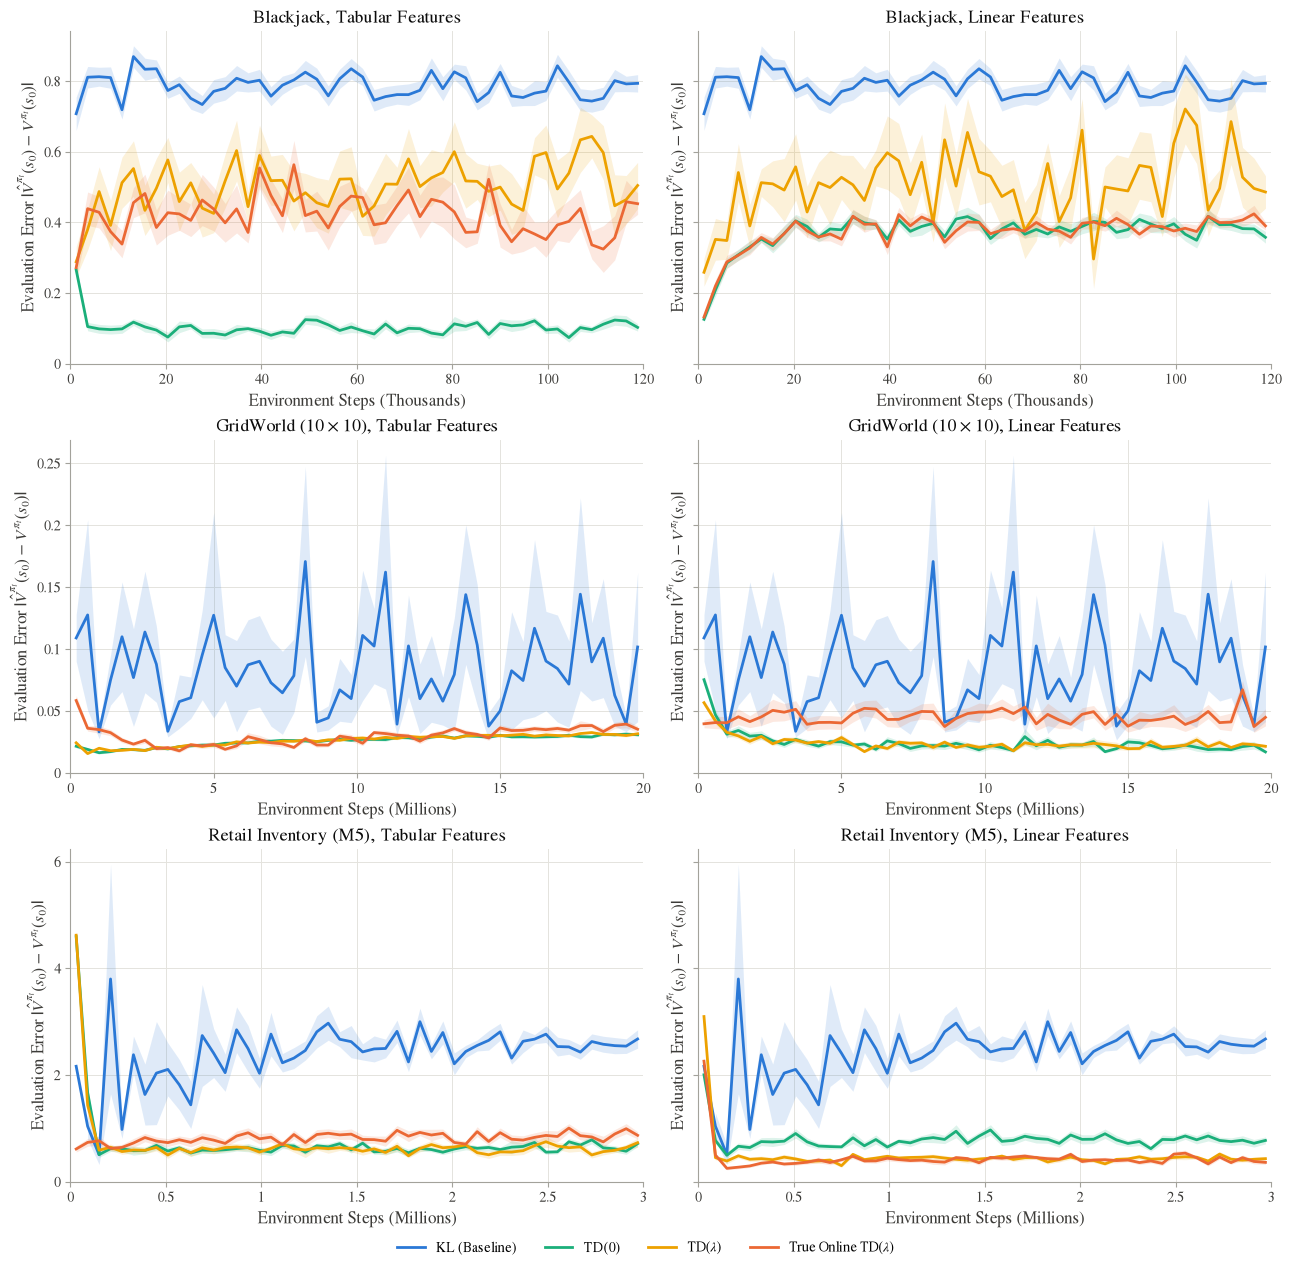

In [4]:
plot_metric("eval_error", r"Evaluation Error $|\hat{V}^{\pi_t}(s_0) - V^{\pi_t}(s_0)|$",
            "fig1_evaluation_error.png", binned=True)

## Figure 2 — Effect on the learned policy

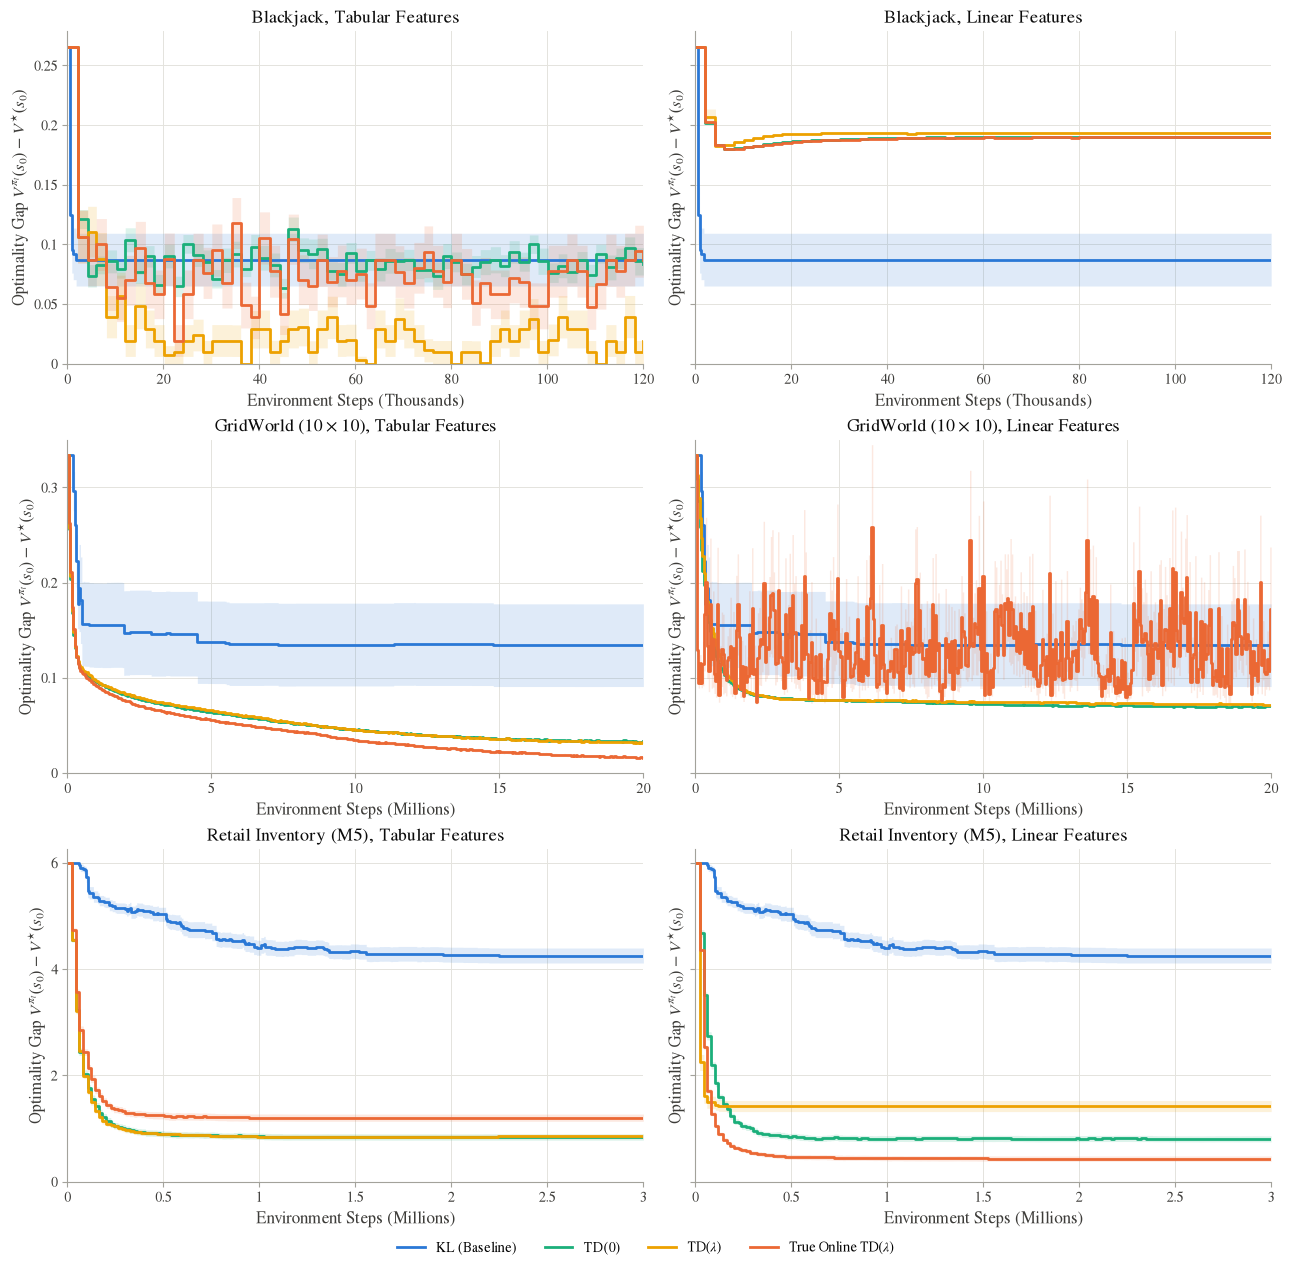

In [5]:
plot_metric("gap", f"Optimality Gap {GAP}", "fig2_optimality_gap.png")

## Table — Observation progression (handout requirement)

Observations used per policy iteration $t$, and how many policy updates each method fits into the budget.
TD spends a fixed amount per evaluation, so every TD variant (tabular or linear) has the same row. TOMC's
stopping rule varies the cost of each evaluation, so we report its mean, median, and range over the 20 seeds.

In [6]:
rows = []
h = runs["Tabular"]
h = h[h.status == "updated"]
for problem in PROBLEMS:
    for method, label in [("baseline", "TOMC (baseline)"), ("td_zero", "TD (all variants)")]:
        d = h[(h.problem == problem) & (h.method == method)]
        updates = d.groupby("seed").iteration.max()
        rows.append({
            "Problem": problem,
            "Budget": obs_label(BUDGET[problem]),
            "Method": label,
            "Obs/iteration (mean)": obs_label(float(f"{d.observations.sum() / len(d):.3g}")),
            "Obs/iteration (median)": obs_label(float(f"{d.observations.median():.3g}")),
            "First iteration (median)": obs_label(float(f"{d[d.iteration == 1].observations.median():.3g}")),
            "Policy updates (mean)": round(updates.mean()),
            "Policy updates (min–max)": f"{updates.min()}–{updates.max()}",
        })
observations_table = pd.DataFrame(rows)
observations_table.to_csv(out / "observation_progression.csv", index=False)
display(observations_table.style.hide(axis="index"))

Problem,Budget,Method,Obs/iteration (mean),Obs/iteration (median),First iteration (median),Policy updates (mean),Policy updates (min–max)
Blackjack,120k,TOMC (baseline),300,274,485,379,1–423
Blackjack,120k,TD (all variants),2k,2k,2k,60,60–60
GridWorld,20M,TOMC (baseline),385k,187k,288k,46,1–152
GridWorld,20M,TD (all variants),50k,50k,50k,400,400–400
Inventory,3M,TOMC (baseline),8.93k,4.21k,100k,336,130–831
Inventory,3M,TD (all variants),20k,20k,20k,150,150–150


## Summary tables — each TD variant vs. the TOMC baseline

* **Eval error**: mean over seeds of each seed's average $|\hat V^{\pi_t}(s_0) - V^{\pi_t}(s_0)|$.
* **Final gap**: $V^{\pi_T}(s_0) - V^{*}(s_0)$ of the last policy, mean ± SE over 20 seeds.
* **Verdict**: $z = \Delta / \sqrt{SE_{TD}^2 + SE_{TOMC}^2}$; *better* if $z < -2$, *worse* if $z > 2$, else *tie*.

In [7]:
def per_seed(history):
    updated = history[history.status == "updated"]
    last = history[history.status.isin(["start", "updated"])].groupby(["problem", "method", "seed"]).tail(1)
    seeds = updated.groupby(["problem", "method", "seed"]).agg(
        eval_error=("eval_error", "mean"), updates=("iteration", "count"),
        obs_total=("observations", "sum"))
    return seeds.join(last.set_index(["problem", "method", "seed"])["gap"])


def summary_table(rep):
    h = runs[rep]
    seeds = per_seed(h)
    g = seeds.groupby(["problem", "method"])
    t = g.mean().join(g["gap"].sem().rename("gap_se")).join(g["eval_error"].sem().rename("err_se"))
    # Pooled over seeds, so a few seeds with huge evaluations do not dominate.
    t["obs_per_update"] = g.obs_total.sum() / g.updates.sum()
    params = h.groupby(["problem", "method"])[["estimator.eta", "estimator.lam", "spmd.step_size"]].first()
    t = t.join(params).reset_index()
    base = t[t.method == "baseline"].set_index("problem")
    t["diff"] = t.gap - t.problem.map(base.gap)
    t["z"] = t["diff"] / np.sqrt(t.gap_se**2 + t.problem.map(base.gap_se)**2)
    t["verdict"] = np.select([t.z < -2, t.z > 2], ["better", "worse"], "tie")
    t.loc[t.method == "baseline", ["diff", "z", "verdict"]] = [np.nan, np.nan, "—"]
    t["method"] = pd.Categorical(t.method.map(LABEL), [LABEL[m] for m in METHODS])
    return pd.DataFrame({
        "Problem": t.problem, "Method": t.method,
        "η": t["estimator.eta"], "λ": t["estimator.lam"], "SPMD step": t["spmd.step_size"],
        "Policy updates": t.updates.round(0).astype(int),
        "Obs/update": t.obs_per_update.map(lambda n: obs_label(float(f"{n:.3g}"))),
        "Eval error": t.eval_error.map("{:.3f}".format) + " ± " + t.err_se.map("{:.3f}".format),
        "Final gap": t.gap.map("{:.3f}".format) + " ± " + t.gap_se.map("{:.3f}".format),
        "Δ gap vs TOMC": t["diff"].round(3),
        "Verdict": t.verdict,
    }).sort_values(["Problem", "Method"]).reset_index(drop=True)


tables = {rep: summary_table(rep) for rep in runs}
for rep, table in tables.items():
    print(f"\n{rep} TD vs. TOMC baseline")
    display(table.style.hide(axis="index").format(na_rep="—", precision=3))
    table.to_csv(out / f"summary_{rep.lower()}.csv", index=False)


Tabular TD vs. TOMC baseline


Problem,Method,η,λ,SPMD step,Policy updates,Obs/update,Eval error,Final gap,Δ gap vs TOMC,Verdict
Blackjack,TOMC (baseline),—,—,100.000,379,300,0.821 ± 0.036,0.087 ± 0.022,—,—
Blackjack,TD(0),0.020,—,10.000,60,2k,0.104 ± 0.002,0.083 ± 0.011,-0.004,tie
Blackjack,TD(λ),0.500,0.950,100.000,60,2k,0.504 ± 0.010,0.019 ± 0.013,-0.068,better
Blackjack,True Online TD(λ),0.500,0.800,100.000,60,2k,0.417 ± 0.007,0.087 ± 0.022,-0.001,tie
GridWorld,TOMC (baseline),—,—,100.000,46,385k,0.078 ± 0.018,0.134 ± 0.043,—,—
GridWorld,TD(0),0.500,—,1.000,400,50k,0.026 ± 0.000,0.033 ± 0.000,-0.101,better
GridWorld,TD(λ),0.100,0.800,1.000,400,50k,0.026 ± 0.000,0.032 ± 0.000,-0.102,better
GridWorld,True Online TD(λ),0.500,0.950,1.000,400,50k,0.030 ± 0.000,0.016 ± 0.001,-0.119,better
Inventory,TOMC (baseline),—,—,1.000,336,8.93k,2.550 ± 0.056,4.255 ± 0.141,—,—
Inventory,TD(0),0.500,—,1.000,150,20k,0.696 ± 0.015,0.839 ± 0.059,-3.416,better



Linear TD vs. TOMC baseline


Problem,Method,η,λ,SPMD step,Policy updates,Obs/update,Eval error,Final gap,Δ gap vs TOMC,Verdict
Blackjack,TOMC (baseline),—,—,100.000,379,300,0.821 ± 0.036,0.087 ± 0.022,—,—
Blackjack,TD(0),0.020,—,1.000,60,2k,0.371 ± 0.002,0.190 ± 0.000,0.103,worse
Blackjack,TD(λ),0.500,0.500,1.000,60,2k,0.504 ± 0.012,0.194 ± 0.000,0.106,worse
Blackjack,True Online TD(λ),0.020,0.500,1.000,60,2k,0.374 ± 0.003,0.190 ± 0.000,0.103,worse
GridWorld,TOMC (baseline),—,—,100.000,46,385k,0.078 ± 0.018,0.134 ± 0.043,—,—
GridWorld,TD(0),0.500,—,1.000,400,50k,0.024 ± 0.001,0.070 ± 0.001,-0.064,tie
GridWorld,TD(λ),0.020,0.950,1.000,400,50k,0.024 ± 0.000,0.072 ± 0.000,-0.063,tie
GridWorld,True Online TD(λ),0.100,0.950,10.000,400,50k,0.045 ± 0.001,0.141 ± 0.043,0.007,tie
Inventory,TOMC (baseline),—,—,1.000,336,8.93k,2.550 ± 0.056,4.255 ± 0.141,—,—
Inventory,TD(0),0.500,—,1.000,150,20k,0.783 ± 0.016,0.804 ± 0.057,-3.451,better
